# Lab 02 ANN & DEEP LEARNING

**Linear Regression from Scratch using Stochastic Gradient Descent — California Housing Dataset**

In this lab you will build a **Linear Regression model completely from scratch**, using only
PyTorch tensors and manual mathematics — no `torch.nn.Linear`, no `torch.optim.SGD`. You will
work with the **California Housing Dataset** to predict median house values from demographic
and geographic features.

By the end of this lab you will have implemented the full machine learning pipeline yourself:
exploratory data analysis, correct train/validation/test splitting, feature standardization,
forward propagation, the L2 (MSE) loss, gradient computation via autograd, a manual
Stochastic Gradient Descent (SGD) update rule, a mini-batch training loop, model evaluation.


# 1. Introduction

## 1.1 Supervised Learning

**Supervised learning** is a branch of machine learning in which a model learns a mapping from
inputs to outputs using a dataset of *labeled examples* — that is, examples for which the
correct output is already known. The model is trained to minimize the difference between its
predictions and the true labels, and the hope is that it generalizes to new, unseen inputs.

Supervised learning problems are generally divided into two categories:

- **Regression** — the target variable \(y\) is continuous (e.g., house price, temperature, stock value).
- **Classification** — the target variable \(y\) is categorical (e.g., spam/not spam, digit 0–9).

In this lab we focus on **regression**, since our goal is to predict a continuous quantity:
the median value of owner-occupied homes in a California district.

## 1.2 What is Linear Regression?

**Linear Regression** is one of the simplest and most interpretable supervised learning
algorithms. It assumes that the target variable \(y\) can be approximated as a **linear
combination** of the input features \(X\), plus a constant offset (the bias).

$$
\hat{y} = Xw + b
$$

Where:

- \(X\) — the matrix of input **features** (each row is one example, each column is one feature).
- \(w\) — the vector of **weights**, one per feature, learned during training.
- \(b\) — the **bias** (intercept) term, learned during training.
- \(\hat{y}\) — the model's **prediction** for the target variable.
- \(y\) — the true **target** value we are trying to predict.

Each weight \(w_j\) represents how strongly feature \(j\) influences the prediction, and in
which direction (positive or negative). The bias \(b\) allows the model to shift its
predictions up or down independently of the input features.

## 1.3 What Does the Model Try to Learn?

The model does **not** know good values of \(w\) and \(b\) in advance. Training is the process
of searching for the values of \(w\) and \(b\) that make the predictions \(\hat{y}\) as close
as possible to the true targets \(y\), across the entire training set. We measure "closeness"
using a **loss function**, and we use an optimization algorithm — in this lab, **Stochastic
Gradient Descent (SGD)** — to iteratively adjust \(w\) and \(b\) so that the loss decreases.

## 1.4 Why is Linear Regression Useful?

- It is simple, fast to train, and easy to interpret — the weights directly tell us how each
  feature affects the prediction.
- It serves as a strong **baseline** against which more complex models (random forests, neural
  networks) are compared.
- It builds the mathematical and coding foundation (forward pass, loss, gradients, parameter
  updates) that underlies almost all modern deep learning models.

## 1.5 Learning Objectives

By the end of this lab, you should be able to:

1. Explain what Linear Regression is and how it makes predictions.
2. Perform exploratory data analysis (EDA) on a real-world tabular dataset.
3. Correctly split data into training, validation, and test sets without leakage.
4. Apply Z-score standardization and explain why it matters for gradient-based optimization.
5. Explain the mechanics of Stochastic Gradient Descent.
6. Implement the forward pass, L2 loss, gradient computation, and manual SGD update from scratch.
7. Build a complete mini-batch training loop using PyTorch `DataLoader`.
8. Evaluate a regression model using MAE, MSE, RMSE, and R².
9. Perform residual analysis to diagnose model behavior.
10. Save and reload trained model parameters.


# 2. Dataset

## 2.1 Load Dataset

We will use the **California Housing Dataset**, available directly through
`sklearn.datasets.fetch_california_housing`. This dataset was derived from the 1990 U.S.
Census and contains block-group-level statistics for California districts. The target
variable is the **median house value** (in units of $100,000s). You can
download: https://www.kaggle.com/datasets/camnugent/california-housing-prices

Let's start by importing the libraries we will need throughout the lab and loading the
dataset.

In [31]:
!pip install torch


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [32]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

print("Libraries imported successfully.")
print("PyTorch version:", torch.__version__)

Libraries imported successfully.
PyTorch version: 2.14.0+cpu


In [33]:
# Load the California Housing dataset as a pandas DataFrame
housing = fetch_california_housing(as_frame=True)

df = housing.frame.copy()
feature_names = housing.feature_names
target_name = "MedHouseVal"

print("Feature names:", feature_names)
print("Number of samples:", df.shape[0])
print("Number of features:", len(feature_names))
print("Target name:", target_name)
print("\nDataset description (excerpt):")
print(housing.DESCR[:600])

Feature names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Number of samples: 20640
Number of features: 8
Target name: MedHouseVal

Dataset description (excerpt):
.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latit


In [34]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 2.2 Dataset Information

Before doing anything else, we should understand the *structure* of the dataset: how many
rows and columns it has, what data type each column is, and whether any values are missing.
`DataFrame.info()` gives us this summary in a single call.

In [35]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


**Observations:**

- The dataset contains **8 numerical input features** plus 1 numerical target column
  (`MedHouseVal`).
- All columns are stored as `float64` — there are no categorical variables to encode.
- Because every feature is purely numerical, we can standardize the entire feature matrix
  directly, without needing one-hot encoding or other categorical preprocessing.

## 2.3 Initial Inspection

Let's look more closely at the raw data: the first and last few rows, the shape of the
dataset, the column names, and summary statistics. This kind of "sanity check" inspection
helps catch obvious data problems (wrong number of rows, unexpected columns, corrupted
values) before we invest time in modeling.

In [36]:
print("Shape of dataset:", df.shape)
print("\nColumn names:", list(df.columns))

Shape of dataset: (20640, 9)

Column names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


In [37]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [38]:
df.tail()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847
20639,2.3886,16.0,5.254717,1.162264,1387.0,2.616981,39.37,-121.24,0.894


In [39]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


**What to look for during initial inspection:**

- **Shape** — confirms the number of examples (20,640) and columns (9, including the target).
- **Column names** — `MedInc` (median income), `HouseAge`, `AveRooms`, `AveBedrms`,
  `Population`, `AveOccup`, `Latitude`, `Longitude`, and the target `MedHouseVal`.
- **Descriptive statistics** — help us notice scale differences between features (e.g.
  `Population` ranges into the thousands while `AveRooms` is typically in single digits),
  which foreshadows why standardization (Section 6) will be important.

# 3. Exploratory Data Analysis (EDA)

**Exploratory Data Analysis (EDA)** is the process of examining a dataset visually and
statistically before modeling. EDA is important because it helps us:

- Understand the **distribution** of each variable (is it symmetric? skewed? bounded?).
- Detect **missing values** that need to be handled.
- Identify **outliers** that could distort training.
- Explore **relationships between variables**, including correlations with the target.
- Build intuition about which features are likely to be useful predictors.

Skipping EDA is a common mistake — a model trained on data you don't understand is much
harder to debug when something goes wrong.

## 3.1 Descriptive Statistics

We already saw `df.describe()` in Section 2.3, but let's re-examine it here with the EDA lens.

In [40]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


Key statistics to focus on:

- **mean** — the average value of the column; useful for understanding a "typical" example.
- **std (standard deviation)** — how spread out the values are around the mean. A large std
  relative to the mean suggests high variability.
- **min / max** — the range of the data. Extreme max values (e.g. `AveRooms` max of 141) can
  be a sign of outliers.
- **25% / 50% / 75% (quartiles)** — the median (50%) and interquartile range give a
  distribution summary that is less sensitive to outliers than the mean and std.

## 3.2 Missing Values

Missing values matter because most machine learning algorithms — including the manual
Linear Regression we will build — cannot operate on `NaN` values directly. Undetected missing
values can silently corrupt gradient computations. Let's check the actual counts in this
dataset.

In [41]:
missing_counts = df.isnull().sum()
missing_summary = pd.DataFrame({
    "Missing Values": missing_counts,
    "Percentage (%)": (missing_counts / len(df) * 100).round(3)
})
missing_summary

,Missing Values,Percentage (%)
MedInc,0,0.0
HouseAge,0,0.0
AveRooms,0,0.0
AveBedrms,0,0.0
Population,0,0.0
AveOccup,0,0.0
Latitude,0,0.0
Longitude,0,0.0
MedHouseVal,0,0.0


In [42]:
total_missing = df.isnull().sum().sum()
print(f"Total missing values in the dataset: {total_missing}")

Total missing values in the dataset: 0


**Interpretation:** The California Housing dataset (as distributed by scikit-learn) contains
**no missing values**, so no imputation is required. In a real-world project you should never
assume this — always check explicitly, as we just did.

## 3.3 Target Distribution

Let's visualize the distribution of the target variable, `MedHouseVal` (median house value,
in units of $100,000).

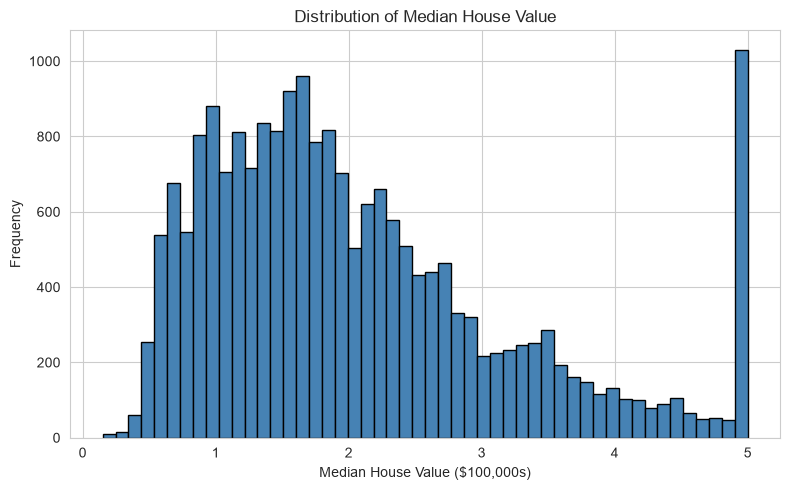

In [43]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df[target_name], bins=50, color="steelblue", edgecolor="black")
ax.set_title("Distribution of Median House Value")
ax.set_xlabel("Median House Value ($100,000s)")
ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

**Interpretation:**

- **Central tendency:** most districts have a median house value roughly between 1 and 3
  (i.e. $100,000–$300,000).
- **Spread:** the distribution has a fairly wide spread, reflecting the diversity of housing
  markets across California.
- **Skewness:** the distribution is **right-skewed** — there is a longer tail toward higher
  values.
- **Unusual values:** there is a noticeable spike at the far right edge (around 5.0). This is
  because the target variable was **capped** at $500,000 during data collection — any true
  value above this was clipped to exactly 5.0. This is worth keeping in mind when interpreting
  errors for the most expensive districts.

## 3.4 Feature Distributions

Now let's look at the distribution of each of the eight input features.

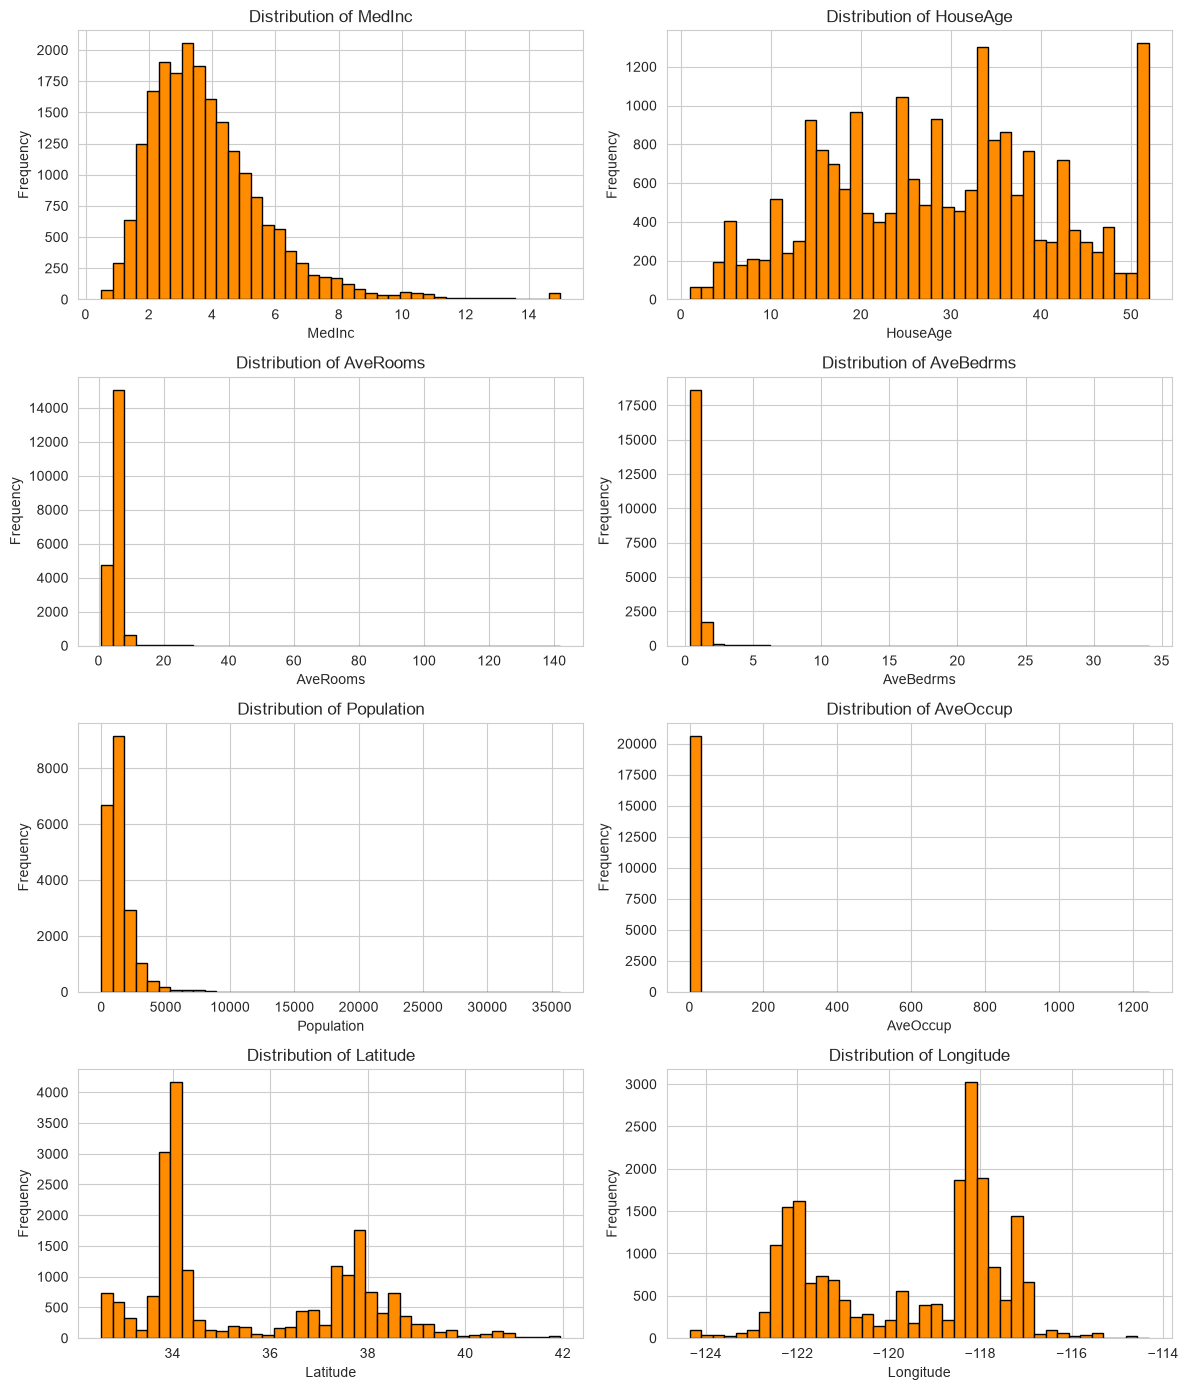

In [44]:
fig, axes = plt.subplots(4, 2, figsize=(12, 14))
axes = axes.flatten()

for i, col in enumerate(feature_names):
    axes[i].hist(df[col], bins=40, color="darkorange", edgecolor="black")
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

**Interpretation:**

- Features such as `MedInc`, `AveRooms`, `AveBedrms`, `Population`, and `AveOccup` are
  **right-skewed**, with long tails caused by a small number of districts with extreme
  values.
- `HouseAge` is more evenly spread, and is capped at 52 (the maximum age recorded).
- `Latitude` and `Longitude` show clusters corresponding to major population centers
  (e.g. the Los Angeles and San Francisco Bay areas) rather than a smooth distribution —
  this reflects real geography, not noise.
- The differing **scales** across features (e.g. `Population` in the thousands vs. `AveRooms`
  in single digits) is exactly the kind of scale mismatch that Z-score standardization
  (Section 6) is designed to fix.

## 3.5 Correlation Analysis

**Correlation** measures the strength and direction of the linear relationship between two
numerical variables, ranging from \(-1\) to \(+1\):

- A **positive correlation** means that as one variable increases, the other tends to
  increase as well.
- A **negative correlation** means that as one variable increases, the other tends to
  decrease.
- A correlation **close to zero** indicates little to no *linear* relationship (there could
  still be a strong non-linear relationship that correlation does not capture).

It is important to remember that **correlation does not imply causation** — two variables can
be correlated because of a shared underlying cause, coincidence, or confounding factors,
without one directly causing the other.

Correlation analysis gives us an early, rough sense of which features might be useful
predictors of the target before we train any model.

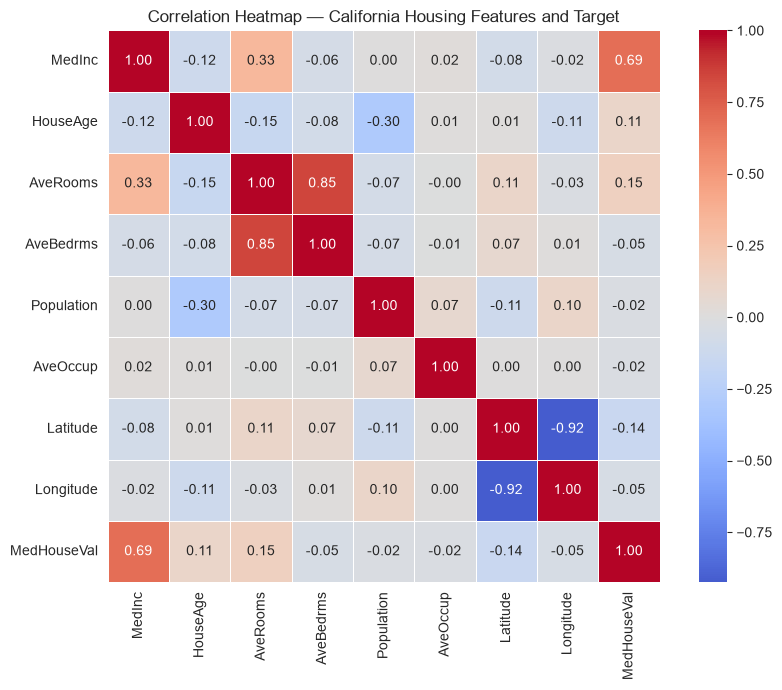

In [45]:
corr_matrix = df.corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlation Heatmap — California Housing Features and Target")
plt.tight_layout()
plt.show()

**Interpretation:**

- `MedInc` (median income) has the **strongest positive correlation** with the target
  `MedHouseVal` — unsurprisingly, wealthier districts tend to have more expensive housing.
- `Latitude` and `Longitude` are negatively correlated with each other and show a moderate
  relationship with the target, reflecting regional price differences across the state.
- `AveRooms` and `AveBedrms` are strongly correlated with each other, which is expected —
  homes with more rooms typically also have more bedrooms. This kind of relationship between
  predictors is called **multicollinearity**, and while it does not prevent Linear Regression
  from making predictions, it can make individual weight values harder to interpret in
  isolation.
- Correlation gives us an *initial* indication of relationships, but Linear Regression will
  ultimately combine **all** features jointly, which can reveal effects that a single
  pairwise correlation cannot.

# 4. Data Splitting

Before training any model, we must divide our data into three separate subsets:

### Training Set
Used to **learn** the model parameters \(w\) and \(b\). The model sees these examples
repeatedly during training and directly adjusts its weights based on them.

### Validation Set
Used **during development** to monitor performance on data the model was *not* trained on.
We use it to track how well the model generalizes, decide when training has converged, and
make development decisions (e.g. choosing a learning rate or number of epochs) — all without
touching the test set.

### Test Set
Used **only once, at the very end**, to obtain an unbiased estimate of how the final model
will perform on completely new data. The test set must not influence any decision made during
model development.

We will use the standard split:

- **70% Training**
- **15% Validation**
- **15% Testing**

**Important — Data Leakage:** *Data leakage* occurs when information from the validation or
test set is used — even indirectly — while training the model or fitting preprocessing
statistics (like the mean and standard deviation used for standardization). Leakage causes
the model to appear more accurate than it really is, because it has effectively "seen" data
it will later be evaluated on. To avoid this, we split the data **first**, and every later
preprocessing step (Section 6) will use statistics computed **only** from the training set.


In [46]:
X = df[feature_names].values
y = df[[target_name]].values  # keep as 2D array (n_samples, 1)

# Step 1: 70% train, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)

# Step 2: split the temporary 30% into 15% validation and 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED
)

n_total = len(X)
print("Split sizes and percentages:")
print(f"  Training:   {X_train.shape[0]:6d} samples ({X_train.shape[0] / n_total * 100:.2f}%)")
print(f"  Validation: {X_val.shape[0]:6d} samples ({X_val.shape[0] / n_total * 100:.2f}%)")
print(f"  Testing:    {X_test.shape[0]:6d} samples ({X_test.shape[0] / n_total * 100:.2f}%)")

print("\nShapes:")
print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_val:  ", X_val.shape,   " y_val:  ", y_val.shape)
print("X_test: ", X_test.shape,  " y_test: ", y_test.shape)

Split sizes and percentages:
  Training:    14448 samples (70.00%)
  Validation:   3096 samples (15.00%)
  Testing:      3096 samples (15.00%)

Shapes:
X_train: (14448, 8)  y_train: (14448, 1)
X_val:   (3096, 8)  y_val:   (3096, 1)
X_test:  (3096, 8)  y_test:  (3096, 1)


**Interpretation:** The split percentages closely match the target 70/15/15 ratio (small
rounding differences are expected due to integer sample counts). From this point forward,
**the test set is set aside and will not be touched again until Section 19 (Model
Evaluation)**.

# 5. Data Preprocessing

Before we can feed our data into a model built with PyTorch, we need to make sure it is in
the right numerical format. Preprocessing at this stage involves:

- Confirming that features (\(X\)) and target (\(y\)) are separated (already done in
  Section 4).
- Converting the NumPy arrays into the correct numerical **data type** (`float32`, which
  PyTorch uses by default for its tensors — using `float64` would work but wastes memory and
  is slower on most hardware).
- Wrapping the arrays as PyTorch **tensors**, since all subsequent computation (forward pass,
  autograd, DataLoader) operates on tensors, not NumPy arrays.

As with the standardization in Section 6, this conversion is applied identically to the
training, validation, and test sets — but always using statistics or logic derived from the
training set alone where any fitting is involved.

In [47]:
# Ensure a consistent, memory-efficient dtype for all splits
X_train = X_train.astype(np.float32)
X_val = X_val.astype(np.float32)
X_test = X_test.astype(np.float32)

y_train = y_train.astype(np.float32)
y_val = y_val.astype(np.float32)
y_test = y_test.astype(np.float32)

print("dtypes after conversion:")
print("X_train:", X_train.dtype, " y_train:", y_train.dtype)

dtypes after conversion:
X_train: float32  y_train: float32


# 6. Normalization / Z-score Standardization

**Normalization** and **standardization** are both techniques for rescaling numerical
features, but they work differently:

- **Normalization** (min-max scaling) rescales values into a fixed range, typically \([0, 1]\).
- **Standardization** (Z-score scaling) rescales values so that they have **mean 0** and
  **standard deviation 1**, without bounding them to a fixed range.

In this lab we use **Z-score standardization**:

$$
z = \frac{x-\mu}{\sigma}
$$

Where:

- \(x\) — the original feature value.
- \(\mu\) — the **mean** of that feature (computed from the training set).
- \(\sigma\) — the **standard deviation** of that feature (computed from the training set).
- \(z\) — the standardized value.

**Why does this matter for SGD?** Our features have very different scales — for example,
`Population` can be in the thousands while `AveBedrms` is close to 1. When features are on
very different scales, the loss surface becomes elongated and "stretched" in certain
directions. This makes gradient descent slow and unstable: a learning rate that works well
for one weight may be far too large or too small for another. Standardizing all features to a
comparable scale makes the loss surface much more symmetric, allowing SGD to converge faster
and more reliably with a single, shared learning rate.

**Critical Data Leakage Rule:** The scaler must be **fit only on the training data**. The
validation and test sets are only ever *transformed* using the mean and standard deviation
already learned from the training set. If we instead fit the scaler on the full dataset (or on
validation/test data), information about the distribution of the validation/test sets would
leak into preprocessing — even though the model itself never sees those labels directly. This
would make our evaluation overly optimistic and not representative of real-world performance.

In [48]:
scaler = StandardScaler()

# Fit ONLY on the training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform validation and test data using the already-fitted scaler
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Training set — mean after scaling (should be ~0):")
print(np.round(X_train_scaled.mean(axis=0), 4))
print("\nTraining set — std after scaling (should be ~1):")
print(np.round(X_train_scaled.std(axis=0), 4))

Training set — mean after scaling (should be ~0):
[-0. -0. -0. -0. -0. -0.  0. -0.]

Training set — std after scaling (should be ~1):
[1. 1. 1. 1. 1. 1. 1. 1.]


**Interpretation:** After standardization, every feature in the **training** set has a mean
very close to 0 and a standard deviation very close to 1, confirming the scaler was fit
correctly. Note that the validation and test sets will **not** have exactly mean 0 / std 1 —
this is expected and correct, since they were transformed using the training set's statistics
rather than their own.

# 7. Stochastic Gradient Descent

Now that our data is ready, we need an algorithm to actually find good values for \(w\) and
\(b\). This is the job of **gradient descent**.

## 7.1 Gradient Descent

Gradient descent is an iterative optimization algorithm. At each step, it computes the
**gradient** of the loss function with respect to the model parameters — a vector that points
in the direction of *steepest increase* of the loss — and then updates the parameters by
moving a small step in the **opposite** direction, since we want to *decrease* the loss.

## 7.2 Batch, Stochastic, and Mini-batch Gradient Descent

- **Batch Gradient Descent** computes the gradient using the **entire** training set before
  making a single parameter update. This gives an accurate gradient estimate but is slow and
  memory-intensive for large datasets.
- **Stochastic Gradient Descent (SGD)** computes the gradient using just **one** randomly
  selected example at a time, then immediately updates the parameters. This makes each update
  extremely fast, but the gradient estimate is noisy.
- **Mini-batch Gradient Descent** is the practical middle ground: it computes the gradient
  using a small, randomly sampled **batch** of examples (e.g. 32 or 64) at a time. This
  balances the computational efficiency of SGD with the more stable gradient estimates of
  batch gradient descent. In modern deep learning, "SGD" almost always refers to this
  mini-batch variant, which is also what we implement in this lab.

## 7.3 The SGD Update Rule

$$
\theta_{new} = \theta_{old} - \eta \, \nabla_{\theta} L
$$

Where:

- \(\theta\) — represents the model's parameters (in our case, \(w\) and \(b\)).
- \(\eta\) (eta) — the **learning rate**, a small positive number controlling how large each
  update step is.
- \(\nabla_{\theta} L\) — the **gradient** of the loss \(L\) with respect to \(\theta\),
  telling us how the loss changes as each parameter changes.

We move in the direction **opposite** the gradient because the gradient points toward
*increasing* loss — moving against it decreases the loss.

## 7.4 Key Terminology

- **Learning rate (\(\eta\))** — controls the step size of each parameter update. Too large,
  and training can diverge or oscillate; too small, and training converges very slowly.
- **Batch size** — the number of examples used to compute each gradient estimate/update.
- **Epoch** — one complete pass through the entire training dataset.
- **Iteration** — one single parameter update, corresponding to processing one mini-batch.
  With a training set of size \(N\) and batch size \(B\), one epoch consists of
  \(\lceil N / B \rceil\) iterations.

## 7.5 Why SGD for Larger Datasets?

For large datasets, computing the exact gradient over *all* examples before every update
(batch gradient descent) is computationally expensive and memory-intensive. Mini-batch SGD
allows the model to make many more frequent — if noisier — updates per epoch, which in
practice often leads to faster convergence and also introduces a small amount of beneficial
noise that can help the optimizer avoid getting stuck in poor local regions of the loss
surface.

# 8. Data Loader

PyTorch's `DataLoader` automates the process of splitting a dataset into shuffled mini-batches
— exactly what mini-batch SGD needs. Rather than manually slicing arrays and tracking indices,
`DataLoader` handles batching, shuffling, and iteration for us.

We first wrap our standardized NumPy arrays into a `TensorDataset` (which simply pairs each
input tensor with its corresponding target tensor), and then wrap that in a `DataLoader`.

- We use `shuffle=True` for the **training** loader, so that the order of examples differs
  every epoch. This prevents the model from learning any spurious patterns related to the
  original ordering of the data.
- We use `shuffle=False` for the **validation** and **test** loaders, since shuffling does not
  matter (and can only make debugging harder) when we are just evaluating the model.

In [49]:
# Convert standardized NumPy arrays into PyTorch tensors
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)

X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32)

X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

# Build TensorDatasets
train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

# Build DataLoaders
batch_size = 64

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Number of training batches:   {len(train_loader)}")
print(f"Number of validation batches: {len(val_loader)}")
print(f"Number of test batches:       {len(test_loader)}")

Number of training batches:   226
Number of validation batches: 49
Number of test batches:       49


In [50]:
# Inspect one sample batch
sample_X, sample_y = next(iter(train_loader))
print("Sample batch X shape:", sample_X.shape, " -> (batch_size, n_features)")
print("Sample batch y shape:", sample_y.shape, " -> (batch_size, 1)")

Sample batch X shape: torch.Size([64, 8])  -> (batch_size, n_features)
Sample batch y shape: torch.Size([64, 1])  -> (batch_size, 1)


**Interpretation:** Each batch of `X` has shape `(batch_size, 8)` — 64 examples, each with 8
standardized features — and each batch of `y` has shape `(batch_size, 1)`, matching the
prediction shape our model will produce.

# 9. Initialize Network

Unlike a deep neural network, Linear Regression needs only **two** learnable parameters:

- A **weight vector** \(w\), with one entry per input feature.
- A single **bias** scalar \(b\).

We deliberately do **not** use `torch.nn.Linear` in this lab — instead, we create these two
tensors manually, so that every subsequent step (forward pass, loss, gradients, updates) is
fully transparent and under your control.

- **Why do we need weights?** Each weight controls how strongly (and in which direction) its
  corresponding feature contributes to the prediction.
- **Why do we need a bias?** The bias lets the model's output be shifted independently of the
  input features — without it, the model would be forced to always predict 0 whenever all
  features are 0, which is an unnecessary restriction.
- **Why `requires_grad=True`?** This tells PyTorch's autograd engine to track every operation
  performed on these tensors, so that it can later automatically compute
  \(\partial L / \partial w\) and \(\partial L / \partial b\) when we call `loss.backward()`.

In [51]:
n_features = X_train_scaled.shape[1]

w = torch.randn(n_features, 1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)

print("Initial weight vector w:")
print(w.detach().numpy().flatten())
print("\nInitial bias b:", b.item())
print("\nw.requires_grad:", w.requires_grad)
print("b.requires_grad:", b.requires_grad)

Initial weight vector w:
[ 0.23446237  0.23033303 -1.1228564  -0.18632829  2.2082014  -0.63799703
  0.46165723  0.26735088]

Initial bias b: 0.0

w.requires_grad: True
b.requires_grad: True


train model 3 times .. w and b all possibilities

# 10. Forward Propagation

**Forward propagation** is the process of computing the model's prediction \(\hat{y}\) given
an input \(X\) and the current parameters \(w\) and \(b\):

$$
\hat{y} = Xw + b
$$

Step by step:

1. Each input example (a row of \(X\)) contains 8 feature values.
2. Each feature value is multiplied by its corresponding weight in \(w\).
3. These 8 weighted contributions are summed together (this is exactly what the matrix
   product \(Xw\) computes for every row at once).
4. The bias \(b\) is added to this sum.
5. The result is the model's prediction \(\hat{y}\) for that example.

When \(X\) has shape `(batch_size, n_features)` and \(w\) has shape `(n_features, 1)`, the
matrix product `X @ w` has shape `(batch_size, 1)` — exactly one prediction per example, which
broadcasts nicely with `b`.

## Forward Propagation

The forward pass of Linear Regression:

$$
\hat{y} = Xw + b
$$

`forward(X, w, b)` accepts `X`, `w`, and `b`, and returns the predicted values `y_hat` with
shape `(batch_size, 1)`, using `torch.matmul` for the matrix multiplication between `X` and `w`.

In [52]:
def forward(X, w, b):
    '''
    Compute the Linear Regression forward pass: y_hat = Xw + b

    Parameters
    ----------
    X : torch.Tensor of shape (batch_size, n_features)
    w : torch.Tensor of shape (n_features, 1)
    b : torch.Tensor of shape (1,)

    Returns
    -------
    y_hat : torch.Tensor of shape (batch_size, 1)
    '''
    y_hat = torch.matmul(X, w) + b
    return y_hat

In [53]:
# ---  Forward Propagation ---
toy_X = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
toy_w = torch.tensor([[0.5], [-1.0]])
toy_b = torch.tensor([0.1])

toy_pred = forward(toy_X, toy_w, toy_b)
expected = torch.tensor([[1.0 * 0.5 + 2.0 * -1.0 + 0.1],
                          [3.0 * 0.5 + 4.0 * -1.0 + 0.1]])

assert toy_pred is not None, "forward() returned None — check your implementation."
assert toy_pred.shape == (2, 1), f"Expected shape (2, 1), got {tuple(toy_pred.shape)}"
assert torch.allclose(toy_pred, expected, atol=1e-5), \
    f"forward() output {toy_pred.tolist()} does not match expected {expected.tolist()}"

print(" forward() is implemented correctly.")

# Sanity check on a real batch from the training set
sample_X, sample_y = next(iter(train_loader))
sample_pred = forward(sample_X, w, b)
print("\nSample prediction shape:", sample_pred.shape)
print("First 5 predictions:", sample_pred[:5].detach().numpy().flatten())

 forward() is implemented correctly.

Sample prediction shape: torch.Size([64, 1])
First 5 predictions: [-2.007166   -2.4110284  -0.76957726 -1.2381903  -2.575992  ]


# 11. L2 Loss

Once the model produces a prediction \(\hat{y}\), we need a way to measure **how wrong** it
is. The **L2 loss**, also known as **Mean Squared Error (MSE)**, is the standard loss function
for regression:

$$
L = \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

- \((y_i - \hat{y}_i)\) is the **prediction error** for example \(i\) — the difference between
  the true value and the predicted value.
- The error is **squared**, which does two things: it makes all errors positive (so positive
  and negative errors don't cancel out), and it penalizes **large** errors much more heavily
  than small ones.
- We then take the **average** over all \(n\) examples, so the loss value does not simply grow
  with the size of the batch or dataset — it represents a *typical* squared error.
- A **lower loss** means the model's predictions are, on average, closer to the true values —
  it does not by itself tell us the sign or direction of typical errors (that's what residual
  analysis in Section 21 is for).



`l2_loss(y_true, y_pred)` computes the element-wise squared difference between `y_true` and
`y_pred`, then takes the mean over all elements.

In [54]:
def l2_loss(y_true, y_pred):
    '''
    Compute the L2 / Mean Squared Error loss.

    Parameters
    ----------
    y_true : torch.Tensor of shape (batch_size, 1)
    y_pred : torch.Tensor of shape (batch_size, 1)

    Returns
    -------
    loss : torch.Tensor (scalar)
    '''
    loss = torch.mean((y_true - y_pred) ** 2)
    return loss

In [55]:
# ---  L2 / MSE Loss ---
toy_y_true = torch.tensor([[3.0], [5.0], [2.0]])
toy_y_pred = torch.tensor([[2.0], [5.0], [4.0]])
# errors: -1, 0, 2  -> squared: 1, 0, 4 -> mean: 5/3

toy_loss = l2_loss(toy_y_true, toy_y_pred)
expected_loss = torch.tensor(5.0 / 3.0)

assert toy_loss is not None, "l2_loss() returned None — check your implementation."
assert torch.allclose(toy_loss, expected_loss, atol=1e-5), \
    f"l2_loss() returned {toy_loss.item()}, expected {expected_loss.item()}"

print(" l2_loss() is implemented correctly.")

# Sanity check with the real model
sample_pred = forward(sample_X, w, b)
sample_loss = l2_loss(sample_y, sample_pred)
print("\nInitial loss on a sample batch (untrained model):", sample_loss.item())

 l2_loss() is implemented correctly.

Initial loss on a sample batch (untrained model): 9.377930641174316


# 12. Gradient Computation

Now that we can compute predictions and a loss, we need to know **how to change** \(w\) and
\(b\) to reduce that loss. This is the role of the **gradient**.

The full sequence of computation looks like this:

```text
Forward Pass
     ↓
Prediction (y_hat)
     ↓
Loss Calculation (L)
     ↓
Backpropagation
     ↓
Gradients (dL/dw, dL/db)
     ↓
Parameter Update
```

The gradient \(\nabla_\theta L\) tells us, for each parameter \(\theta\) (i.e. each entry of
\(w\), and \(b\)), **how much the loss would change** if we increased that parameter by a tiny
amount. A positive gradient means increasing the parameter would increase the loss (so we
should decrease it); a negative gradient means the opposite.

PyTorch's **autograd** engine can compute all of these gradients for us automatically. Because
we created `w` and `b` with `requires_grad=True`, PyTorch has been silently recording every
operation performed on them since Section 9. Calling `.backward()` on a scalar loss walks
backward through that recorded computation graph and populates `w.grad` and `b.grad` with
\(\partial L/\partial w\) and \(\partial L/\partial b\), respectively.

## Compute Gradients via Autograd

Using the `forward()` and `l2_loss()` functions above, we compute the gradients of the loss
with respect to `w` and `b` for one sample batch:

1. Run the forward pass to get predictions.
2. Compute the loss.
3. Call `.backward()` on the loss to populate the gradients.
4. Store the resulting gradients in `grad_w` and `grad_b`.

In [56]:
# Compute the gradients of the loss with respect to w and b, using autograd.
#
# Steps:
#   1. Run the forward pass on `sample_X` using `forward(sample_X, w, b)`.
#   2. Compute the loss between `sample_y` and your predictions using `l2_loss`.
#   3. Call `.backward()` on the loss.
#   4. Store the resulting gradients in the variables `grad_w` and `grad_b` below.

sample_pred = forward(sample_X, w, b)
sample_loss = l2_loss(sample_y, sample_pred)
sample_loss.backward()

grad_w = w.grad
grad_b = b.grad

In [57]:
# --- Verification: Gradient Computation ---
assert grad_w is not None, "grad_w is still None — did you call loss.backward() and assign w.grad?"
assert grad_b is not None, "grad_b is still None — did you call loss.backward() and assign b.grad?"
assert grad_w.shape == w.shape, f"grad_w shape {tuple(grad_w.shape)} does not match w shape {tuple(w.shape)}"
assert grad_b.shape == b.shape, f"grad_b shape {tuple(grad_b.shape)} does not match b shape {tuple(b.shape)}"

print(" Gradients were computed successfully.")
print("\ndL/dw (first 5 entries):", grad_w.flatten()[:5].tolist())
print("dL/db:", grad_b.item())


 Gradients were computed successfully.

dL/dw (first 5 entries): [-2.2758736610412598, 0.5552250146865845, -0.535886824131012, 0.34160637855529785, 2.8721237182617188]
dL/db: -4.863616466522217


# 13. SGD Optimization

Now that we have gradients, we can update the parameters using the **manual SGD update
rule**:

$$
w := w - \eta\frac{\partial L}{\partial w}
$$

$$
b := b - \eta\frac{\partial L}{\partial b}
$$

We subtract (rather than add) the gradient because the gradient points in the direction of
**increasing** loss — moving in the opposite direction decreases the loss. The learning rate
\(\eta\) controls how big each step is.

**Important:** Parameter updates must be performed inside a `with torch.no_grad():` block.
Without it, PyTorch's autograd would try to track the update operation itself as part of the
computation graph, which is not what we want — we are *modifying* the parameters directly, not
computing a new differentiable quantity from them. `torch.no_grad()` temporarily disables
gradient tracking for the code inside the block, which is exactly right for a raw
in-place parameter update.

We must also remember to **clear the gradients** after each update (`w.grad.zero_()` and
`b.grad.zero_()`), because by default PyTorch **accumulates** gradients across multiple
`.backward()` calls rather than overwriting them. If we forget this step, gradients from
previous batches would incorrectly add onto the current batch's gradients.

## Manual SGD Update

`sgd_update(w, b, learning_rate)` updates `w` and `b` in place using the gradients already
stored in `w.grad` and `b.grad`, then resets those gradients to zero so they don't accumulate
into the next iteration.

**No `torch.optim.SGD` is used** — the update rule is implemented manually.

In [58]:
def sgd_update(w, b, learning_rate):
    '''
    Perform one manual SGD parameter update using the gradients already
    stored in w.grad and b.grad, then reset those gradients to zero.

    Parameters
    ----------
    w : torch.Tensor of shape (n_features, 1), with w.grad populated
    b : torch.Tensor of shape (1,), with b.grad populated
    learning_rate : float, the step size eta

    Returns
    -------
    None (w and b are updated in place)
    '''
    with torch.no_grad():
        w -= learning_rate * w.grad
        b -= learning_rate * b.grad

    w.grad.zero_()
    b.grad.zero_()

In [59]:
# --- Verification: Manual SGD Update ---
test_w = torch.tensor([[1.0], [2.0]], requires_grad=True)
test_b = torch.tensor([0.5], requires_grad=True)

test_X = torch.tensor([[1.0, 1.0], [2.0, 1.0]])
test_y = torch.tensor([[0.0], [0.0]])

test_pred = forward(test_X, test_w, test_b)
test_loss = l2_loss(test_y, test_pred)
test_loss.backward()

w_before = test_w.detach().clone()
b_before = test_b.detach().clone()
grad_w_before = test_w.grad.detach().clone()
grad_b_before = test_b.grad.detach().clone()

sgd_update(test_w, test_b, learning_rate=0.1)

expected_w = w_before - 0.1 * grad_w_before
expected_b = b_before - 0.1 * grad_b_before

assert torch.allclose(test_w.detach(), expected_w, atol=1e-5), "w was not updated correctly."
assert torch.allclose(test_b.detach(), expected_b, atol=1e-5), "b was not updated correctly."
assert torch.all(test_w.grad == 0), "w.grad was not reset to zero after the update."
assert torch.all(test_b.grad == 0), "b.grad was not reset to zero after the update."

print("sgd_update() is implemented correctly.")

sgd_update() is implemented correctly.


# 14. Training

**Training** a model means repeatedly applying the forward pass, loss calculation, gradient
computation, and parameter update — across many mini-batches and many passes over the data —
so that the loss gradually decreases and the model's predictions improve.

Key terminology recap:

- **Epoch** — one complete pass through the entire training dataset.
- **Mini-batch** — a small subset of the training data (here, 64 examples) used for a single
  parameter update.
- **Forward pass** → **Loss** → **Backward pass** → **Gradients** → **SGD update** — the
  four-step cycle repeated for every mini-batch.
- **Validation loss** — computed on the (untouched-by-training) validation set after each
  epoch, to monitor whether the model is actually generalizing rather than just memorizing
  the training data.

The full cycle, repeated for every batch in every epoch, looks like this:

```text
Training Batch
      ↓
Forward Pass
      ↓
Prediction
      ↓
L2 Loss
      ↓
Backward Pass
      ↓
Gradients
      ↓
SGD Update
      ↓
Next Batch
      ↓
Next Epoch
```

Note that we compute the validation loss with `torch.no_grad()` and **do not** call
`.backward()` or `sgd_update()` on it — the validation set is only used to *monitor*
performance, never to update the model's parameters.

## Training Loop

Using the building blocks already implemented (`forward`, `l2_loss`, `sgd_update`), the loop
below trains the model. For each epoch:

1. Iterate over all mini-batches in `train_loader`.
2. For each batch: run the forward pass, compute the loss, call `loss.backward()`, and call
   `sgd_update(w, b, learning_rate)`.
3. Track the **average training loss** for the epoch, weighted by batch size.
4. Loop over `val_loader` **without** gradient tracking (`torch.no_grad()`), and track the
   **average validation loss** for the epoch.
5. Append the epoch's average training and validation loss to `train_losses` / `val_losses`.
6. Print the training and validation loss every few epochs.

In [66]:
learning_rate = 0.01

In [71]:

for X_batch, y_batch in train_loader:
        y_pred = forward(X_batch, w, b)
        loss = l2_loss(y_batch, y_pred)
        loss.backward()
        sgd_update(w, b, learning_rate)
        running_train_loss += loss.item() * X_batch.size(0)
        n_train_seen += X_batch.size(0)
        print(X_batch)

tensor([[ 1.1322e+00, -1.4727e+00,  3.3511e-01, -2.6722e-01, -1.5723e-02,
         -4.7507e-02, -1.1896e+00,  1.1704e+00],
        [-6.4210e-01,  1.0643e+00, -7.4129e-01, -2.3454e-01, -1.8412e-01,
          8.8522e-02, -8.0100e-01,  6.8107e-01],
        [-3.8633e-01, -1.2490e-01, -4.0274e-01,  7.7538e-01, -8.8751e-01,
         -8.3991e-02, -8.3378e-01,  8.1089e-01],
        [ 6.3476e-01, -9.1772e-01,  7.8319e-01, -9.1379e-02,  2.5616e-01,
         -1.8466e-02, -5.3410e-01,  1.1854e+00],
        [ 4.9259e-01, -6.0059e-01,  3.7129e-01, -1.4748e-01,  2.5792e-01,
         -1.7405e-02, -1.1522e+00,  1.1854e+00],
        [-9.7241e-01, -9.9700e-01, -5.5225e-02,  2.2566e-01, -3.4374e-01,
         -1.1438e-01, -1.1381e+00,  1.1754e+00],
        [ 2.7998e-01,  4.3008e-01,  2.6921e-01, -1.2112e-01,  3.1638e-02,
          7.2069e-02, -7.4481e-01,  8.1089e-01],
        [ 1.5988e+00, -4.4203e-01,  6.6510e-01, -1.6416e-01,  1.4112e+00,
         -2.0102e-02, -6.7926e-01,  4.6638e-01],
        [ 9.9132

In [84]:
# Re-initialize fresh parameters before training
torch.manual_seed(SEED)
w = torch.randn(n_features, 1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)

learning_rate = 0.01
n_epochs = 60

train_losses = []
val_losses = []

patience = 5
bestloss = float("inf")
best_w=None
best_b=None
counter=0

for epoch in range(1, n_epochs + 1):
    # --- Training phase ---
    running_train_loss = 0.0
    n_train_seen = 0
    for X_batch, y_batch in train_loader:
        y_pred = forward(X_batch, w, b)
        loss = l2_loss(y_batch, y_pred)
        loss.backward()
        sgd_update(w, b, learning_rate)
        running_train_loss += loss.item() * X_batch.size(0)
        n_train_seen += X_batch.size(0)
    epoch_train_loss = running_train_loss / n_train_seen

    # --- Validation phase  ---
    running_val_loss = 0.0
    n_val_seen = 0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            y_pred = forward(X_batch, w, b)
            loss = l2_loss(y_batch, y_pred)
            running_val_loss += loss.item() * X_batch.size(0)
            n_val_seen += X_batch.size(0)
    epoch_val_loss = running_val_loss / n_val_seen
    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    if epoch_val_loss < bestloss:
        bestloss=epoch_val_loss
        best_w=w.detach().clone()
        best_b=b.detach().clone()
        counter = 0
    else:
        counter += 1
    if counter >= patience:
        print(f"Early stopping at epoch {epoch} due to no improvement in validation loss for {patience} consecutive epochs.")
        break

    

    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d}/{n_epochs} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")

print("\nTraining complete." if train_losses else "Training loop not yet implemented.")

Epoch   1/60 | Train Loss: 1.9689 | Val Loss: 0.7373
Epoch   5/60 | Train Loss: 0.5564 | Val Loss: 0.5608
Epoch  10/60 | Train Loss: 0.5291 | Val Loss: 0.5445
Epoch  15/60 | Train Loss: 0.5262 | Val Loss: 0.5429
Early stopping at epoch 17 due to no improvement in validation loss for 5 consecutive epochs.

Training complete.


train with 0.1,0.001.0.0001 LR 10 epochs enough...1 time 60 epochs
0.01:
Epoch  10/10 | Train Loss: 0.5291 | Val Loss: 0.5445
0.001:
Epoch  10/10 | Train Loss: 0.7279 | Val Loss: 0.7329
0.0001:
Epoch  10/10 | Train Loss: 4.9203 | Val Loss: 4.9484


add early stopping


In [85]:
# ---  Training Loop ---
assert len(train_losses) == len(val_losses), \
    f"Training and val loss have diff lengths"

assert train_losses[-1] < train_losses[0], \
    "Training loss did not decrease ."

print(" The model trained successfully.")
print(f"\nFinal training loss:   {train_losses[-1]:.4f}")
print(f"Final validation loss: {bestloss:.4f}")

 The model trained successfully.

Final training loss:   0.5252
Final validation loss: 0.5414


# 15. Training Visualization

Plotting the training and validation loss curves side by side is one of the most useful
diagnostic tools in machine learning. Let's visualize how both losses evolved across epochs.

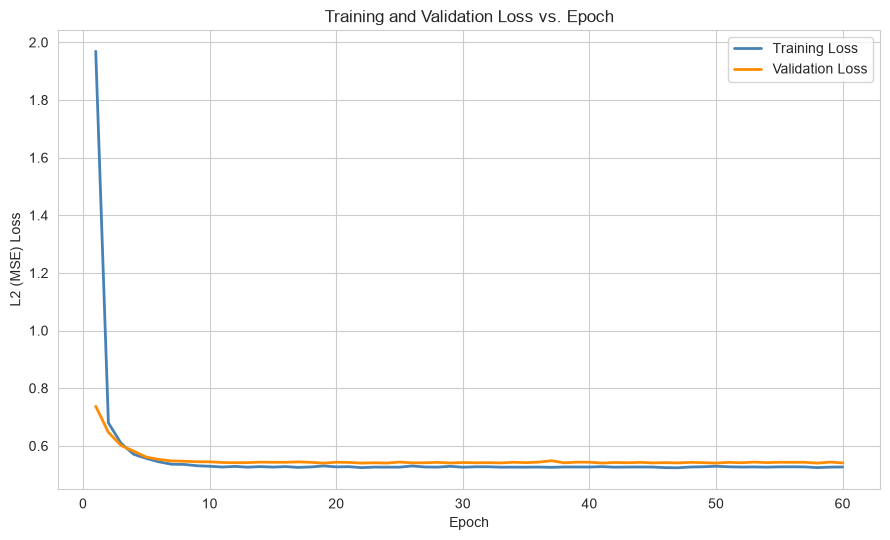

In [73]:
fig, ax = plt.subplots(figsize=(9, 5.5))
epochs_range = range(1, n_epochs + 1)

ax.plot(epochs_range, train_losses, label="Training Loss", color="steelblue", linewidth=2)
ax.plot(epochs_range, val_losses, label="Validation Loss", color="darkorange", linewidth=2)
ax.set_title("Training and Validation Loss vs. Epoch")
ax.set_xlabel("Epoch")
ax.set_ylabel("L2 (MSE) Loss")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation — how to read a loss curve:**

- **Good convergence:** both the training and validation losses decrease steadily and then
  stabilize at a similarly low level, with only a small, consistent gap between them.
- **Underfitting:** both losses remain relatively high and flatten out early, without reaching
  a low value. This suggests the model (or its training procedure) is too limited to capture
  the patterns in the data — for a linear model, this can indicate that the true relationship
  is substantially non-linear, or that the learning rate/number of epochs is insufficient.
- **Overfitting:** the training loss keeps decreasing while the validation loss flattens out or
  starts *increasing* — the model is starting to fit noise specific to the training set rather
  than genuine patterns. This is less common for a simple Linear Regression model (which has
  very limited capacity) but is an essential concept for the more complex models you will see
  later in the course.
- **Unstable training:** the loss curve oscillates wildly or diverges (increases without
  bound). This is usually a sign that the learning rate is too high — try lowering it and
  retraining.

# 16. Save Model

Once a model is trained, we need to be able to **save** it so that it can be reused later —
for further evaluation, deployment, or simply to avoid retraining from scratch every time. In
our case, "the model" consists of:

- The learned **weights** (`w`).
- The learned **bias** (`b`).
- The **scaler statistics** (mean and standard deviation from `StandardScaler`), since any new
  raw input must be standardized in exactly the same way before being passed to the model.
- Basic **configuration/metadata** (e.g. the feature names and the learning rate used), which
  makes the saved file self-documenting.

We use PyTorch's `torch.save`, which can serialize a Python dictionary containing tensors and
other metadata into a single file.

In [74]:
model_checkpoint = {
    "w": w.detach().clone(),
    "b": b.detach().clone(),
    "scaler_mean": torch.tensor(scaler.mean_, dtype=torch.float32),
    "scaler_scale": torch.tensor(scaler.scale_, dtype=torch.float32),
    "feature_names": feature_names,
    "learning_rate": learning_rate,
    "n_epochs": n_epochs,
    "batch_size": batch_size,
}

save_path = "linear_regression_california_housing.pth"
torch.save(model_checkpoint, save_path)

print(f"Model saved to '{save_path}'.")
print("Contents saved:", list(model_checkpoint.keys()))

Model saved to 'linear_regression_california_housing.pth'.
Contents saved: ['w', 'b', 'scaler_mean', 'scaler_scale', 'feature_names', 'learning_rate', 'n_epochs', 'batch_size']


# 17. Load Model

To confirm the save was successful — and to demonstrate how the model could be restored in a
completely separate session — let's load the checkpoint back and verify that it can still
produce predictions matching the trained model.

Being able to reliably save and reload trained parameters (together with the exact
preprocessing statistics used at training time) is essential for **reproducibility** and for
eventually **deploying** a model into a real application, where predictions must be made using
the same transformation pipeline used during training.

In [75]:
loaded_checkpoint = torch.load(save_path, weights_only=False)

w_loaded = loaded_checkpoint["w"]
b_loaded = loaded_checkpoint["b"]

print("Loaded weight shape:", w_loaded.shape)
print("Loaded bias:", b_loaded.item())
print("Loaded feature names:", loaded_checkpoint["feature_names"])

Loaded weight shape: torch.Size([8, 1])
Loaded bias: 2.070478677749634
Loaded feature names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [76]:
# Verify that the loaded parameters reproduce identical predictions on a sample batch
with torch.no_grad():
    original_pred = forward(sample_X, w, b)
    loaded_pred = forward(sample_X, w_loaded, b_loaded)

assert torch.allclose(original_pred, loaded_pred, atol=1e-6), \
    "Predictions from the loaded model do not match the original model!"

print("predictions from the loaded model exactly match the original model.")

predictions from the loaded model exactly match the original model.


# 18. Test Function

To avoid repeating the same prediction logic every time we want to evaluate the model on a
dataset, let's write one reusable function, `get_predictions`, that:

- Accepts a `DataLoader` (or a plain input tensor) and the model parameters.
- Runs the forward pass over the entire dataset (without gradient tracking, since we are only
  doing inference here).
- Returns the model's predictions and the true target values, both as flat NumPy arrays ready
  for use with `sklearn.metrics` functions.

In [77]:
def get_predictions(data_loader, w, b):
    '''Run the model over an entire DataLoader and collect predictions and true targets.'''
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            y_pred = forward(X_batch, w, b)
            all_preds.append(y_pred)
            all_targets.append(y_batch)

    all_preds = torch.cat(all_preds, dim=0).numpy().flatten()
    all_targets = torch.cat(all_targets, dim=0).numpy().flatten()
    return all_preds, all_targets

In [78]:
# Quick check on the validation set
val_preds_check, val_targets_check = get_predictions(val_loader, w, b)
print("Number of validation predictions:", len(val_preds_check))
print("First 5 predictions:", np.round(val_preds_check[:5], 3))
print("First 5 true values: ", np.round(val_targets_check[:5], 3))

Number of validation predictions: 3096
First 5 predictions: [1.361 3.291 3.956 2.878 1.989]
First 5 true values:  [1.225 3.204 4.507 2.343 1.019]


# 19. Model Evaluation

A single metric rarely tells the whole story about a regression model's performance. We will
compute four complementary metrics:

### Mean Absolute Error (MAE)

$$
MAE = \frac{1}{n}\sum_{i=1}^{n} |y_i-\hat{y}_i|
$$

The average absolute size of the prediction errors, in the **same units** as the target. Easy
to interpret directly, and not overly sensitive to a few large outliers.

### Mean Squared Error (MSE)

$$
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

The same L2 loss we trained on — squares the errors, so larger errors are penalized much more
heavily. Its units are the *square* of the target's units, which makes it less directly
interpretable than MAE.

### Root Mean Squared Error (RMSE)

$$
RMSE = \sqrt{MSE}
$$

Takes the square root of MSE to bring the units back to the same scale as the target,
while still penalizing large errors more than MAE does.

### R² (Coefficient of Determination)

R² measures the proportion of variance in the target that is explained by the model, relative
to a naive baseline that always predicts the mean of the target. It ranges up to 1.0 (a
perfect model); a value of 0 means the model performs no better than always predicting the
mean, and negative values mean the model performs *worse* than that trivial baseline.

We will compute all four metrics on the **training**, **validation**, and **test** sets, so we
can compare performance across all three and check for any signs of overfitting.

In [79]:
train_preds, train_targets = get_predictions(train_loader, w, b)
val_preds, val_targets = get_predictions(val_loader, w, b)
test_preds, test_targets = get_predictions(test_loader, w, b)

def compute_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

metrics_train = compute_metrics(train_targets, train_preds)
metrics_val = compute_metrics(val_targets, val_preds)
metrics_test = compute_metrics(test_targets, test_preds)

metrics_df = pd.DataFrame(
    [metrics_train, metrics_val, metrics_test],
    index=["Training", "Validation", "Test"]
).round(4)

metrics_df

,MAE,MSE,RMSE,R2
Training,0.5314,0.5251,0.7247,0.6080
Validation,0.5339,0.5421,0.7363,0.5839
Test,0.5214,0.5268,0.7258,0.6016


# 20. Actual vs Predicted

A scatter plot of actual values against predicted values, on the **test set**, gives us an
intuitive visual sense of prediction quality. We also draw the line \(y=x\): if the model were
perfect, every point would fall exactly on this line.

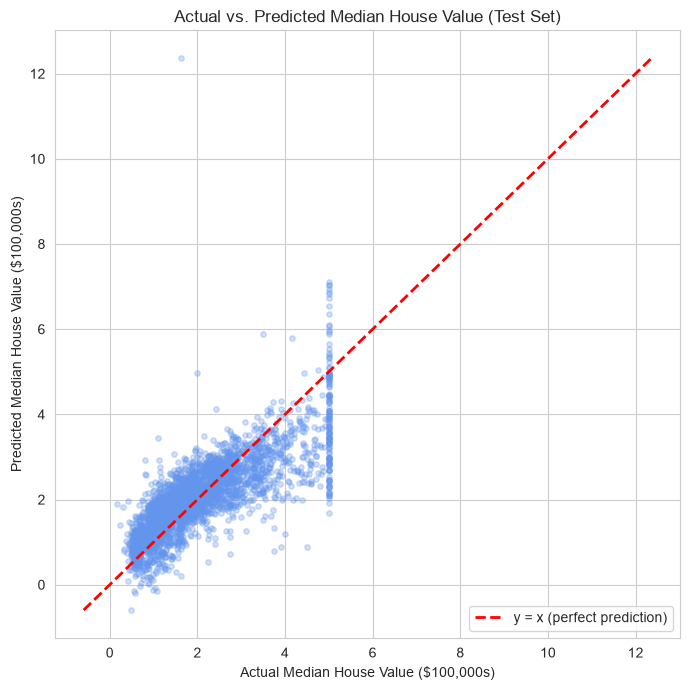

In [80]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(test_targets, test_preds, alpha=0.3, s=15, color="Cornflowerblue")

lims = [min(test_targets.min(), test_preds.min()), max(test_targets.max(), test_preds.max())]
ax.plot(lims, lims, color="red", linestyle="--", linewidth=2, label="y = x (perfect prediction)")

ax.set_title("Actual vs. Predicted Median House Value (Test Set)")
ax.set_xlabel("Actual Median House Value ($100,000s)")
ax.set_ylabel("Predicted Median House Value ($100,000s)")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation:** Points that fall close to the red \(y=x\) line represent accurate
predictions; the further a point is from the line, the larger the prediction error for that
example. Notice the vertical band of points near `Actual = 5.0` — this corresponds to the
capped target values we observed in Section 3.3, where the true value could be anywhere at or
above $500,000 but was recorded as exactly 5.0. The model cannot know this cap exists, so it
naturally under- or over-predicts many of these capped examples, contributing to the spread
seen at the right edge of the plot.

# 21. Residual Analysis

A **residual** is the difference between the true value and the predicted value:

$$
e_i = y_i - \hat{y}_i
$$

Residual analysis helps us understand **how** the model is wrong, not just by how much.
Patterns in the residuals can reveal problems that a single aggregate metric (like R²) would
hide — for example, the model might be systematically biased for certain ranges of
predictions.

In [81]:
residuals = test_targets - test_preds
print("Residual summary statistics:")
print(pd.Series(residuals).describe())

Residual summary statistics:
count    3096.000000
mean       -0.016387
std         0.725713
min       -10.740137
25%        -0.465242
50%        -0.133078
75%         0.299137
max         3.621620
dtype: float64


## 21.1 Residual Histogram

If the model's errors are unbiased and well-behaved, we would expect the residuals to be
roughly centered around zero and approximately symmetric.

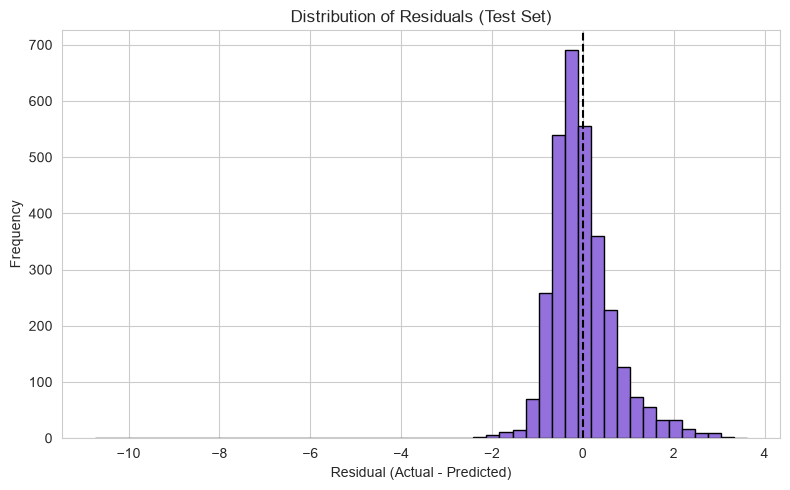

In [82]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(residuals, bins=50, color="mediumpurple", edgecolor="black")
ax.axvline(0, color="black", linestyle="--", linewidth=1.5)
ax.set_title("Distribution of Residuals (Test Set)")
ax.set_xlabel("Residual (Actual - Predicted)")
ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

## 21.2 Residual vs Predicted Plot

Plotting residuals against the predicted values helps reveal **systematic patterns** that a
histogram alone cannot show.

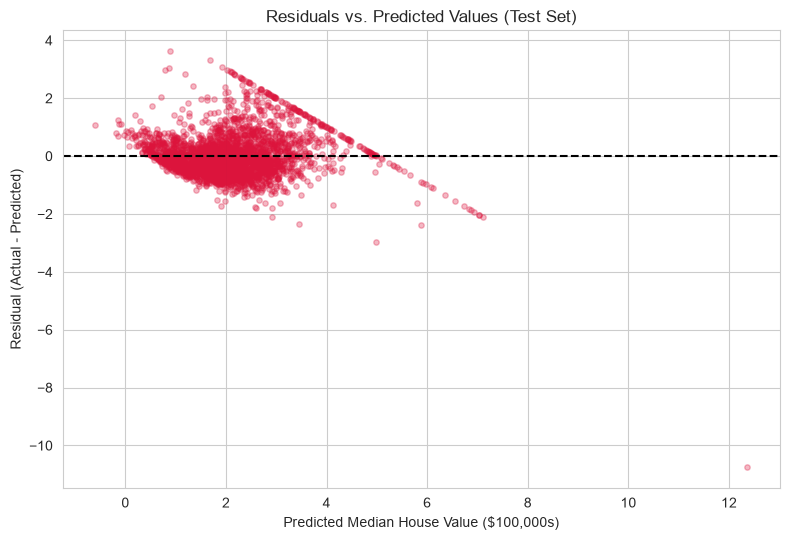

In [83]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(test_preds, residuals, alpha=0.3, s=15, color="crimson")
ax.axhline(0, color="black", linestyle="--", linewidth=1.5)
ax.set_title("Residuals vs. Predicted Values (Test Set)")
ax.set_xlabel("Predicted Median House Value ($100,000s)")
ax.set_ylabel("Residual (Actual - Predicted)")
plt.tight_layout()
plt.show()

**Interpretation — what to look for:**

- **Random scatter** around zero, with no obvious shape, suggests the model's errors are not
  systematically related to the predicted value — a sign of a reasonably well-specified model.
- **Systematic patterns** (e.g. a curve, or a clear upward/downward trend) suggest the true
  relationship between features and target may be non-linear in ways a linear model cannot
  capture.
- **Increasing variance** (a "funnel" or "fan" shape, where the spread of residuals grows as
  predicted values increase) indicates **heteroscedasticity** — the model's errors are not
  uniform across the range of predictions.
- **Large outliers** — a small number of points far from the rest — can disproportionately
  affect MSE/RMSE, and are worth investigating individually.




## Task:

Using the `residuals`, `test_preds`, and `test_targets` arrays you already computed:

1. **Identify the worst predictions.** Find the 5 test examples with the *largest absolute
   residual*. Print their actual value, predicted value, and residual.
2. **Check for heteroscedasticity.** Split the test set into 3 equal-sized bins by
   `test_preds` (low / medium / high predicted value), and compute the **standard deviation
   of the residuals** within each bin. Does the spread increase as predicted value increases?
3. **Investigate the capped targets.** Recall that `MedHouseVal` is capped at 5.00001 in this
   dataset. Filter for test examples where `test_targets >= 5.0` and compute their mean
   residual separately. How does the model perform on these capped examples compared to the
   rest of the test set?
4. **Written reflection (2–3 sentences):** Based on your findings above, is this Linear
   Regression model *equally* trustworthy across the full range of house values, or are there
   specific regions where you'd be cautious about its predictions? Justify your answer using
   the numbers you computed.